In [1]:
import pandas as pd
import re
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# Load dataset
df = pd.read_csv("fakenews.csv")

# Handle missing values
df["headline"] = df["headline"].fillna("").astype(str)
df["body_text"] = df["body_text"].fillna("").astype(str)

# Combine headline and body text
df["text"] = df["headline"] + " " + df["body_text"]

print("Dataset loaded successfully!")
print("Total articles:", len(df))

print("\nNews categories:")
print(df["label"].value_counts())

print("\nSample data:")
print(df[["label", "text"]].head())

Dataset loaded successfully!
Total articles: 2212

News categories:
label
Fake    1110
Real    1102
Name: count, dtype: int64

Sample data:
  label                                               text
0  Real  Global economy faces recession The Prime Minis...
1  Real  Earthquake hits Chittagong, panic spreads Gove...
2  Fake  Breakthrough in Bangladesh's tech industry Loc...
3  Fake  Dengue situation worsens in the country The Pr...
4  Real  New virus outbreak sparks fear Government sour...


In [2]:
# Function to clean text
def clean_text(text):
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", "", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

# Apply text cleaning
df["clean_text"] = df["text"].apply(clean_text)

print(df[["label", "clean_text"]].head())
print("\nText cleaning completed!")

  label                                         clean_text
0  Real  global economy faces recession the prime minis...
1  Real  earthquake hits chittagong panic spreads gover...
2  Fake  breakthrough in bangladesh s tech industry loc...
3  Fake  dengue situation worsens in the country the pr...
4  Real  new virus outbreak sparks fear government sour...

Text cleaning completed!


In [3]:
# Convert text into word-count features
vectorizer = CountVectorizer(
    stop_words="english",
    max_df=0.95,
    min_df=2,
    max_features=5000
)

dtm = vectorizer.fit_transform(df["clean_text"])

print("Document-Term Matrix created!")
print("Matrix shape:", dtm.shape)
print("Number of articles:", dtm.shape[0])
print("Number of unique words:", dtm.shape[1])

Document-Term Matrix created!
Matrix shape: (2212, 98)
Number of articles: 2212
Number of unique words: 98


In [4]:
# Set the number of topics
num_topics = 5

# Create and train the LDA model
lda_model = LatentDirichletAllocation(
    n_components=num_topics,
    random_state=42,
    max_iter=10,
    learning_method="batch"
)

lda_model.fit(dtm)

print("LDA model trained successfully!")
print("Number of topics:", num_topics)

LDA model trained successfully!
Number of topics: 5


In [5]:
# Get all words from the document-term matrix
words = vectorizer.get_feature_names_out()

# Display top 10 words for each topic
for topic_index, topic in enumerate(lda_model.components_):
    top_word_indices = topic.argsort()[-10:][::-1]
    top_words = [words[i] for i in top_word_indices]

    print(f"\nTopic {topic_index + 1}:")
    print(", ".join(top_words))


Topic 1:
remains, authenticity, incident, uncertainty, announces, job, reforms, major, government, ceremony

Topic 2:
city, various, incidents, authorities, reported, parts, investigating, morning, recession, economy

Topic 3:
social, went, viral, news, noon, media, help, precautions, danger, advise

Topic 4:
experts, quite, conspiracy, calling, natural, say, curriculum, introduced, schools, new

Topic 5:
residents, witnessed, claim, event, outbreak, virus, sparks, fear, new, government


In [6]:
#  Get topic probabilities for each article
topic_probabilities = lda_model.transform(dtm)

# Assign the most likely topic to each article
df["dominant_topic"] = topic_probabilities.argmax(axis=1) + 1

# Add topic probabilities to a DataFrame
topic_columns = [
    f"Topic_{i + 1}" for i in range(num_topics)
]

topic_df = pd.DataFrame(
    topic_probabilities,
    columns=topic_columns,
    index=df.index
)

# Add news category and dominant topic
topic_df["label"] = df["label"]
topic_df["dominant_topic"] = df["dominant_topic"]

# Compare dominant topic counts
topic_comparison = pd.crosstab(
    topic_df["dominant_topic"],
    topic_df["label"]
)

print("Dominant Topic Distribution in Real and Fake News:\n")
print(topic_comparison)

# Compare average topic probabilities
print("\nAverage Topic Probabilities by News Category:\n")
print(topic_df.groupby("label")[topic_columns].mean().round(3))

Dominant Topic Distribution in Real and Fake News:

label           Fake  Real
dominant_topic            
1                239   192
2                224   209
3                312   363
4                120   120
5                215   218

Average Topic Probabilities by News Category:

       Topic_1  Topic_2  Topic_3  Topic_4  Topic_5
label                                             
Fake     0.217    0.218    0.235    0.125    0.205
Real     0.187    0.213    0.272    0.131    0.197


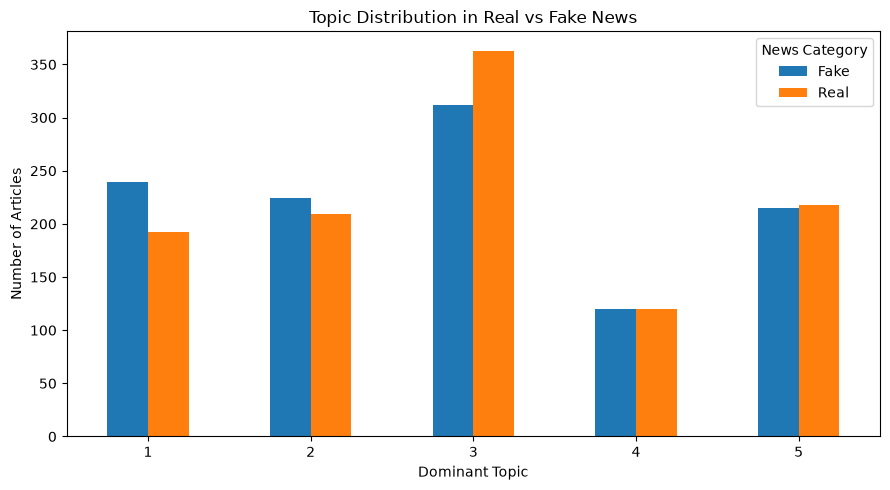

In [7]:
# Plot topic distribution
topic_comparison.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Topic Distribution in Real vs Fake News")
plt.xlabel("Dominant Topic")
plt.ylabel("Number of Articles")
plt.xticks(rotation=0)
plt.legend(title="News Category")
plt.tight_layout()
plt.show()

In [8]:
# Save article-level topic assignments
df.to_csv("T25_lda_topic_assignments.csv", index=False)

# Save topic probabilities for each article
topic_df.to_csv("T25_topic_probabilities.csv", index=False)

# Save topic distribution comparison
topic_comparison.to_csv("T25_topic_comparison.csv")

# Display results
print("Topic Distribution:\n")
print(topic_comparison)

print("\nTop Words in Each Topic:")
for topic_index, topic in enumerate(lda_model.components_):
    top_indices = topic.argsort()[-10:][::-1]
    top_words = [words[i] for i in top_indices]
    print(f"Topic {topic_index + 1}: {', '.join(top_words)}")

print("\nLDA topic modeling completed successfully!")

Topic Distribution:

label           Fake  Real
dominant_topic            
1                239   192
2                224   209
3                312   363
4                120   120
5                215   218

Top Words in Each Topic:
Topic 1: remains, authenticity, incident, uncertainty, announces, job, reforms, major, government, ceremony
Topic 2: city, various, incidents, authorities, reported, parts, investigating, morning, recession, economy
Topic 3: social, went, viral, news, noon, media, help, precautions, danger, advise
Topic 4: experts, quite, conspiracy, calling, natural, say, curriculum, introduced, schools, new
Topic 5: residents, witnessed, claim, event, outbreak, virus, sparks, fear, new, government

LDA topic modeling completed successfully!
